# 2장 퍼셉트론 — 연습 문제

책 2장 순서(2.1 → 2.5)를 따른다. 해당 절을 읽고 나서 그 Part를 풀자.
`# 여기에 작성`을 채우고 실행(`Shift+Enter`)한 뒤 확인 셀에서 `통과!`가 나오면 성공.
막히면 `ch02_solutions.ipynb` 참고. 커널은 `.venv`.

## 0. 준비
아래 셀을 먼저 실행하자. 게이트 함수를 넣으면 진리표 4가지를 모두 검사해 준다.

In [1]:
# 진리표 채점 도우미 (먼저 실행해 두기)
def check_gate(gate, expected, name):
    inputs = [(0, 0), (1, 0), (0, 1), (1, 1)]
    ok = True
    for (x1, x2), want in zip(inputs, expected):
        got = gate(x1, x2)
        mark = '✅' if got == want else '❌'
        if got != want:
            ok = False
        print(f'{name}({x1}, {x2}) = {got}   (정답 {want}) {mark}')
    assert ok, f'{name} 진리표가 맞지 않아요'
    print('통과!')


# Part 1. 퍼셉트론이란 (2.1)
## 2-1. 손으로 계산해 보기
입력 $x_1, x_2$, 가중치 $w_1, w_2$, 임계값 $\theta$일 때

$$y = \begin{cases} 0 & (w_1x_1 + w_2x_2 \le \theta) \\ 1 & (w_1x_1 + w_2x_2 > \theta) \end{cases}$$

$x_1=1,\ x_2=0,\ w_1=0.3,\ w_2=0.8,\ \theta=0.5$일 때
- `s`: $w_1x_1 + w_2x_2$ 값
- `y`: 출력 (0 또는 1)

**코드 전에 종이에 먼저 계산해 보자.**

In [2]:
x1, x2 = 1, 0
w1, w2, theta = 0.3, 0.8, 0.5
s = 0.3
y = 0


In [3]:
# 확인
assert abs(s - 0.3) < 1e-9 and y == 0
print('통과!')

통과!


# Part 2. 논리 회로 (2.2)
## 2-2. AND 게이트의 매개변수 찾기
| $x_1$ | $x_2$ | AND |
|:-:|:-:|:-:|
| 0 | 0 | 0 |
| 1 | 0 | 0 |
| 0 | 1 | 0 |
| 1 | 1 | **1** |

둘 다 1일 때만 1이 되도록 `w1, w2, theta`를 **직접 골라 보자.** 정답은 여러 개다.
> 힌트: 하나만 1일 때의 합은 θ 이하, 둘 다 1일 때의 합은 θ 초과가 되어야 한다.

In [4]:
def AND(x1, x2):
    w1, w2, theta = 0.5, 0.5, 0.8

    return 1 if (x1*w1 + x2*w2) > theta else 0

In [5]:
# 확인
check_gate(AND, [0, 0, 0, 1], 'AND')

AND(0, 0) = 0   (정답 0) ✅
AND(1, 0) = 0   (정답 0) ✅
AND(0, 1) = 0   (정답 0) ✅
AND(1, 1) = 1   (정답 1) ✅
통과!


## 2-3. NAND, OR 게이트 직접 만들기
| $x_1$ | $x_2$ | NAND | OR |
|:-:|:-:|:-:|:-:|
| 0 | 0 | 1 | 0 |
| 1 | 0 | 1 | 1 |
| 0 | 1 | 1 | 1 |
| 1 | 1 | 0 | 1 |

AND와 **같은 모양의 함수**로, 매개변수만 바꿔서 NAND와 OR를 만들자.
> 생각해 보기: NAND는 AND의 반대다. 가중치와 θ의 **부호**를 모두 뒤집으면?

In [6]:
def NAND(x1, x2):
    w1 , w2, theta = -0.5, -0.5, -0.7
    return 1 if (w1*x1 + w2*x2) > theta else 0

def OR(x1, x2):
    w1, w2, theta = 0.5, 0.5, 0.3
    return 1 if (w1*x1 + w2*x2) > theta else 0

In [7]:
# 확인
check_gate(NAND, [1, 1, 1, 0], 'NAND')
check_gate(OR, [0, 1, 1, 1], 'OR')

NAND(0, 0) = 1   (정답 1) ✅
NAND(1, 0) = 1   (정답 1) ✅
NAND(0, 1) = 1   (정답 1) ✅
NAND(1, 1) = 0   (정답 0) ✅
통과!
OR(0, 0) = 0   (정답 0) ✅
OR(1, 0) = 1   (정답 1) ✅
OR(0, 1) = 1   (정답 1) ✅
OR(1, 1) = 1   (정답 1) ✅
통과!


**생각해 보기** (답을 주석으로 적어 보자)
- AND, NAND, OR는 **함수 모양이 똑같고 매개변수만** 다르다. 이게 무슨 의미일까?
- 사람이 매개변수를 고르는 대신, 컴퓨터가 데이터를 보고 **스스로 고르게** 하는 것이 '학습'이다. (4장)

In [ ]:
# 내 생각: 실게 값이 있다면 해당 값에 퍼셉트론 통과 후에 정답하고 비교해서 정답에 가까운 퍼셉트론이 되도록 만들게 한다. 


# Part 3. 퍼셉트론 구현하기 (2.3)
## 2-4. 편향(bias) 도입하기
$\theta$를 왼쪽으로 넘기고 $b = -\theta$로 쓰면

$$y = \begin{cases} 0 & (b + w_1x_1 + w_2x_2 \le 0) \\ 1 & (b + w_1x_1 + w_2x_2 > 0) \end{cases}$$

NumPy 배열로 AND를 다시 만들자.
- `x = np.array([x1, x2])`, `w = np.array([w1, w2])`
- 합은 `np.sum(w * x) + b` (1장의 원소별 곱!)
- 2-2에서 고른 값을 쓰면 `b = -theta`

In [8]:
#AND 함수 구현하기
import numpy as np

def AND(x1, x2):
    x = np.array([x1, x2])
    w = np.array([0.5, 0.5])
    b = -0.7

    return 1 if sum(x*w) + b > 0 else 0
    

In [ ]:
import numpy as np

def AND(x1, x2):
    x = np.array([x1, x2])
    w = None  # 여기에 작성
    b = None
    tmp = None
    return 1 if tmp > 0 else 0


In [9]:
# 확인
check_gate(AND, [0, 0, 0, 1], 'AND')

AND(0, 0) = 0   (정답 0) ✅
AND(1, 0) = 0   (정답 0) ✅
AND(0, 1) = 0   (정답 0) ✅
AND(1, 1) = 1   (정답 1) ✅
통과!


In [13]:
def NAND(x1, x2):
    x = np.array([x1, x2])
    w = np.array([-0.5, -0.5])
    b = 0.7

    return 1 if sum(w*x) + b > 0 else 0

def OR(x1, x2):
    x = np.array([x1, x2])
    w =  np.array([0.5, 0.5])
    b = -0.3
    return 1 if sum(w*x)+b > 0 else 0

In [14]:
# 확인
check_gate(NAND, [1, 1, 1, 0], 'NAND')
check_gate(OR, [0, 1, 1, 1], 'OR')

NAND(0, 0) = 1   (정답 1) ✅
NAND(1, 0) = 1   (정답 1) ✅
NAND(0, 1) = 1   (정답 1) ✅
NAND(1, 1) = 0   (정답 0) ✅
통과!
OR(0, 0) = 0   (정답 0) ✅
OR(1, 0) = 1   (정답 1) ✅
OR(0, 1) = 1   (정답 1) ✅
OR(1, 1) = 1   (정답 1) ✅
통과!


# Part 4. 퍼셉트론의 한계 (2.4)
## 2-6. OR의 경계선 그려 보기
퍼셉트론의 경계는 $b + w_1x_1 + w_2x_2 = 0$ 인 **직선**이다.
OR($w=[0.5, 0.5],\ b=-0.2$)의 경계는 $x_2 = -x_1 + 0.4$ 이다.

4개 점을 출력값에 따라 다른 모양으로 찍고, 경계 직선을 그려 보자.
- 출력 0: `'o'` (동그라미), 출력 1: `'^'` (세모)
- 힌트: `plt.scatter(x, y, marker='o')`, 직선은 1장의 `plt.plot`

In [ ]:
import matplotlib.pyplot as plt

points = [(0, 0), (1, 0), (0, 1), (1, 1)]
# 여기에 작성

plt.xlim(-0.5, 1.5)
plt.ylim(-0.5, 1.5)
plt.show()


## 2-7. XOR은 직선 하나로 나눌 수 있을까?
| $x_1$ | $x_2$ | XOR |
|:-:|:-:|:-:|
| 0 | 0 | 0 |
| 1 | 0 | 1 |
| 0 | 1 | 1 |
| 1 | 1 | 0 |

2-6처럼 XOR의 4개 점을 찍어 보자. 그리고 **직선 하나로** 동그라미와 세모를 나눌 수 있는지 생각해 보자.
> 이게 **단층 퍼셉트론의 한계**다. 직선(선형)으로 나눌 수 있는 영역만 표현할 수 있다.

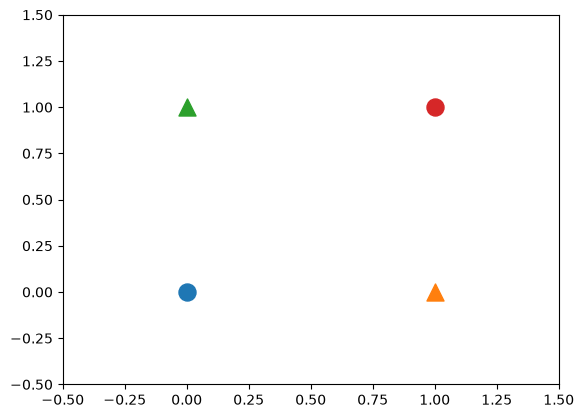

In [21]:
import matplotlib.pyplot as plt

xor_out = {(0, 0): 0, (1, 0): 1, (0, 1): 1, (1, 1): 0}

for (x1, x2), y in xor_out.items():
    plt.scatter(x1, x2, marker='^' if y == 1 else 'o', s=150)

plt.xlim(-0.5, 1.5)
plt.ylim(-0.5, 1.5)
plt.show()


# Part 5. 다층 퍼셉트론 (2.5)
## 2-8. 게이트를 조합해 XOR 만들기
직선 하나로는 안 되지만, **층을 쌓으면** 된다. 아래 표의 빈칸을 머릿속으로 채워 보자.

| $x_1$ | $x_2$ | $s_1$ = NAND | $s_2$ = OR | AND($s_1$, $s_2$) |
|:-:|:-:|:-:|:-:|:-:|
| 0 | 0 | ? | ? | ? |
| 1 | 0 | ? | ? | ? |
| 0 | 1 | ? | ? | ? |
| 1 | 1 | ? | ? | ? |

마지막 열이 XOR과 같아지면 성공이다. 이 구조로 `XOR(x1, x2)`를 만들자.
> 힌트: 앞에서 만든 NAND, OR, AND 함수를 **그대로 불러서** 쓰면 된다. 새 매개변수는 필요 없다.

In [ ]:
def XOR(x1, x2):
    #NAND OR 게이트의 중첩을 통해서 구현할 수 있음. 마지막을 AND 게이트를 통하게 한다. 

    x = np.array([x1, x2])
    w_nand = np.array([-0.5, -0.5])
    b_nand = 0.7

    w_or = np.array([0.5, 0.5])
    b_or = -0.4

    temp_nand = np.sum(w_nand*x)+b_nand 
    temp_or = np.sum(w_or*x) + b_or

    return 1 if (temp_nand > 0 and temp_or > 0 ) else 0





"""
    def XOR(x1, x2):
    s1 = NAND(x1, x2)    # 1층
    s2 = OR(x1, x2)      # 1층
    y = AND(s1, s2)      # 2층: 1층의 출력이 2층의 입력이 됨
    return y
"""
# 퍼셉트론 형식으로 작성할 수 있음. 

In [24]:
# 확인
check_gate(XOR, [0, 1, 1, 0], 'XOR')

XOR(0, 0) = 0   (정답 0) ✅
XOR(1, 0) = 1   (정답 1) ✅
XOR(0, 1) = 1   (정답 1) ✅
XOR(1, 1) = 0   (정답 0) ✅
통과!


**생각해 보기**
- XOR은 몇 층짜리 퍼셉트론일까? (입력층 = 0층으로 셀 때)
- 단층으로 안 되던 것이 층을 쌓자 됐다. 이게 3장 '신경망'으로 이어지는 핵심 아이디어다.
- 책 2.6절: NAND 게이트만 조합해도 이론상 **컴퓨터**까지 만들 수 있다.

In [ ]:
# 내 생각: 2층짜리 퍼셉트론인 거 같아